In [1]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras import layers
#tensorflow : DL framework
#numpy : handles numerical operations
#matplotlib : displays images
#layers : provider dense, conv2D , flatten , etc.

In [2]:
#step 3 :load MNIST dataset
#MNIST contains 70000 handwritten digit image
#60000 training images
# 10000 testing images
# each image has dimensions 28 x 28
# each image contains a digit between 0 and 9

#load Mnist dataset
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data()

#check dataset shape
print("Training data:",x_train.shape)
print("Testing data:",x_test.shape)

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
Training data: (60000, 28, 28)
Testing data: (10000, 28, 28)


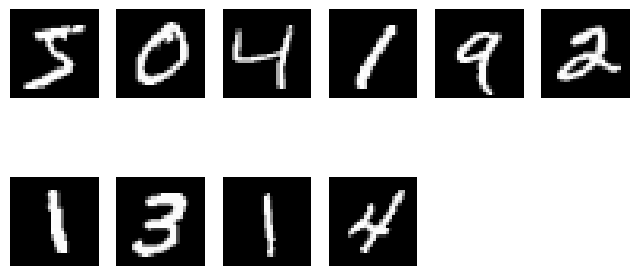

In [3]:
#Display some original images
plt.figure(figsize=(8,4))
for i in range(10):
  plt.subplot(2,6, i+1)
  plt.imshow(x_train[i], cmap='gray')
  plt.axis('off')
plt.show()

In [4]:
x_train = x_train.astype('float32')
#normalize pixel values from 0-255 to -1 to +1
x_train = (x_train - 127.5) / 127.5
#add channel dimension
x_train = np.expand_dims(x_train, axis=-1)
print(x_train.shape)
#why do we add the channel dimension?
#because CNN models expect image data in this format:
#(height,width,channels)

(60000, 28, 28, 1)


In [5]:
#step5 prepare the training dataset
BUFFER_SIZE = 60000
BATCH_SIZE = 256
train_dataset = tf.data.Dataset.from_tensor_slices(x_train)
train_dataset = train_dataset.shuffle(BUFFER_SIZE)
train_dataset = train_dataset.batch(BATCH_SIZE)
#explaination
# - shuffle(): Randomly changes image order
# - batch(): divides images into groups of 256
# from_tensor_slices(): conerts our trainig images
#into a tensorflow

In [6]:

# Step 6: Create the Generator
# Now we will build our first neural network.
# The Generator takes 100 random numbers and generates a 28 × 28 image.
def build_generator():
    model = tf.keras.Sequential()
    # Input: 100 random numbers
    model.add(layers.Input(shape=(100,)))
    # Convert noise into 7*7*128 values
    model.add(layers.Dense(7 * 7 * 128))

    # Normalize values
    model.add(layers.BatchNormalization())

    # Apply activation
    model.add(layers.LeakyReLU())

    # Reshape into feature maps
    model.add(layers.Reshape((7, 7, 128)))

    # Increase image size from 7x7 to 14x14
    model.add(
        layers.Conv2DTranspose(
            64,
            kernel_size=5,
            strides=2,
            padding="same"
        )
    )

    model.add(layers.BatchNormalization())

    model.add(layers.LeakyReLU())

    # Increase image size from 14x14 to 28x28
    model.add(
        layers.Conv2DTranspose(
            1,
            kernel_size=5,
            strides=2,
            padding="same",
            activation="tanh"
        )
    )

    return model

In [7]:
#create  the generator
generator = build_generator()
generator.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 6272)           │       633,472 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 6272)           │        25,088 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu (LeakyReLU)         │ (None, 6272)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape (Reshape)               │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose                │ (None, 14, 14, 64)     │       204,864 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 14, 14, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_1 (LeakyReLU)       │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_1              │ (None, 28, 28, 1)      │         1,601 │
│ (Conv2DTranspose)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 865,281 (3.30 MB)

 Trainable params: 852,609 (3.25 MB)

 Non-trainable params: 12,672 (49.50 KB)

In [8]:
#generate 1 random noise vector
noise = tf.random.normal([1, 100])
#generate an image
generated_image = generator(noise, training=False)
print(generated_image.shape)

(1, 28, 28, 1)


In [9]:
# Step 7: Create the Discriminator
# Now let's create the second neural network.
# The Discriminator receives an image and predicts whether it is real or fake.
def build_discriminator():

    model = tf.keras.Sequential()

    # Input image: 28x28 grayscale
    model.add(layers.Input(shape=(28, 28, 1)))

    # First convolution layer
    model.add(
        layers.Conv2D(
            64,
            kernel_size=5,
            strides=2,
            padding="same"
        )
    )

    model.add(layers.LeakyReLU())

    model.add(layers.Dropout(0.3))

    # Second convolution layer
    model.add(
        layers.Conv2D(
            128,
            kernel_size=5,
            strides=2,
            padding="same"
        )
    )

    model.add(layers.LeakyReLU())

    model.add(layers.Dropout(0.3))

    # Convert feature maps into a vector
    model.add(layers.Flatten())

    # Final output
    model.add(layers.Dense(1))

    return model

In [10]:
discriminator = build_discriminator()
discriminator.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 14, 14, 64)     │         1,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_2 (LeakyReLU)       │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 7, 7, 128)      │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_3 (LeakyReLU)       │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 6272)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │         6,273 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 212,865 (831.50 KB)

 Trainable params: 212,865 (831.50 KB)

 Non-trainable params: 0 (0.00 B)

In [11]:
cross_entropy = tf.keras.losses.BinaryCrossentropy(
    from_logits=True
)

In [12]:
# Discriminator Loss:
# The Discriminator should identify real images as 1 and fake images as 0.
def discriminator_loss(real_output, fake_output):

    real_loss = cross_entropy(
        tf.ones_like(real_output),
        real_output
    )

    fake_loss = cross_entropy(
        tf.zeros_like(fake_output),
        fake_output
    )

    total_loss = real_loss + fake_loss

    return total_loss

In [13]:
# Step 9: Define optimizers
# We use Adam optimizers to update the weights of both networks.
generator_optimizer = tf.keras.optimizers.Adam(
    learning_rate=0.0002,
    beta_1=0.5
)

discriminator_optimizer = tf.keras.optimizers.Adam(
    learning_rate=0.0002,
    beta_1=0.5
)

# Why two optimizers?
# Because the Generator and Discriminator have different trainable weights
# and are trained separately.

In [14]:
# Define the noise dimension
noise_dim = 100

# Recreate the models to ensure a clean state and build variables immediately
generator = build_generator()
discriminator = build_discriminator()

# Recreate the optimizers so they bind to the correct, new variables
generator_optimizer = tf.keras.optimizers.Adam(
    learning_rate=0.0002,
    beta_1=0.5
)

discriminator_optimizer = tf.keras.optimizers.Adam(
    learning_rate=0.0002,
    beta_1=0.5
)

# Call the models once on dummy noise/images to instantiate their weights before training starts
_ = generator(tf.random.normal([1, 100]), training=False)
_ = discriminator(tf.random.normal([1, 28, 28, 1]), training=False)

# Define the Generator Loss (which was missing)
def generator_loss(fake_output):
    return cross_entropy(tf.ones_like(fake_output), fake_output)

# Redefine train_step to point to the newly recreated models and optimizers
@tf.function
def train_step(real_images):
    batch_size = tf.shape(real_images)[0]
    noise = tf.random.normal([batch_size, noise_dim])

    # Train Discriminator
    with tf.GradientTape() as disc_tape:
        generated_images = generator(noise, training=True)
        real_output = discriminator(real_images, training=True)
        fake_output = discriminator(tf.stop_gradient(generated_images), training=True)
        disc_loss = discriminator_loss(real_output, fake_output)

    disc_gradients = disc_tape.gradient(disc_loss, discriminator.trainable_variables)
    discriminator_optimizer.apply_gradients(zip(disc_gradients, discriminator.trainable_variables))

    # Train Generator
    noise = tf.random.normal([batch_size, noise_dim])
    with tf.GradientTape() as gen_tape:
        generated_images = generator(noise, training=True)
        fake_output = discriminator(generated_images, training=True)
        gen_loss = generator_loss(fake_output)

    gen_gradients = gen_tape.gradient(gen_loss, generator.trainable_variables)
    generator_optimizer.apply_gradients(zip(gen_gradients, generator.trainable_variables))

    return gen_loss, disc_loss

# Fix dataset shape in case of multiple runs
(x_train, _), (_, _) = tf.keras.datasets.mnist.load_data()
x_train = x_train.astype('float32')
x_train = (x_train - 127.5) / 127.5
x_train = np.expand_dims(x_train, axis=-1)

# Recreate training dataset
train_dataset = tf.data.Dataset.from_tensor_slices(x_train)
train_dataset = train_dataset.shuffle(BUFFER_SIZE).batch(BATCH_SIZE)

# Now we will train both networks safely.
EPOCHS = 30

for epoch in range(EPOCHS):
    gen_loss_total = 0
    disc_loss_total = 0
    batches = 0

    for image_batch in train_dataset:
        gen_loss, disc_loss = train_step(image_batch)
        gen_loss_total += gen_loss
        disc_loss_total += disc_loss
        batches += 1

    print(
        f"Epoch {epoch + 1}/{EPOCHS} | "
        f"Generator Loss: {gen_loss_total / batches:.4f} | "
        f"Discriminator Loss: {disc_loss_total / batches:.4f}"
    )

Epoch 1/30 | Generator Loss: 0.7849 | Discriminator Loss: 1.2125
Epoch 2/30 | Generator Loss: 0.8013 | Discriminator Loss: 1.3233
Epoch 3/30 | Generator Loss: 0.8117 | Discriminator Loss: 1.3001
Epoch 4/30 | Generator Loss: 0.8809 | Discriminator Loss: 1.2402
Epoch 5/30 | Generator Loss: 0.9672 | Discriminator Loss: 1.1785
Epoch 6/30 | Generator Loss: 0.9597 | Discriminator Loss: 1.1674
Epoch 7/30 | Generator Loss: 0.9949 | Discriminator Loss: 1.2193
Epoch 8/30 | Generator Loss: 0.9189 | Discriminator Loss: 1.2238
Epoch 9/30 | Generator Loss: 0.9182 | Discriminator Loss: 1.2454
Epoch 10/30 | Generator Loss: 0.8864 | Discriminator Loss: 1.2524
Epoch 11/30 | Generator Loss: 0.8978 | Discriminator Loss: 1.2643
Epoch 12/30 | Generator Loss: 0.8775 | Discriminator Loss: 1.2618
Epoch 13/30 | Generator Loss: 0.8837 | Discriminator Loss: 1.2676
Epoch 14/30 | Generator Loss: 0.8786 | Discriminator Loss: 1.2696
Epoch 15/30 | Generator Loss: 0.8779 | Discriminator Loss: 1.2672
Epoch 16/30 | Gener

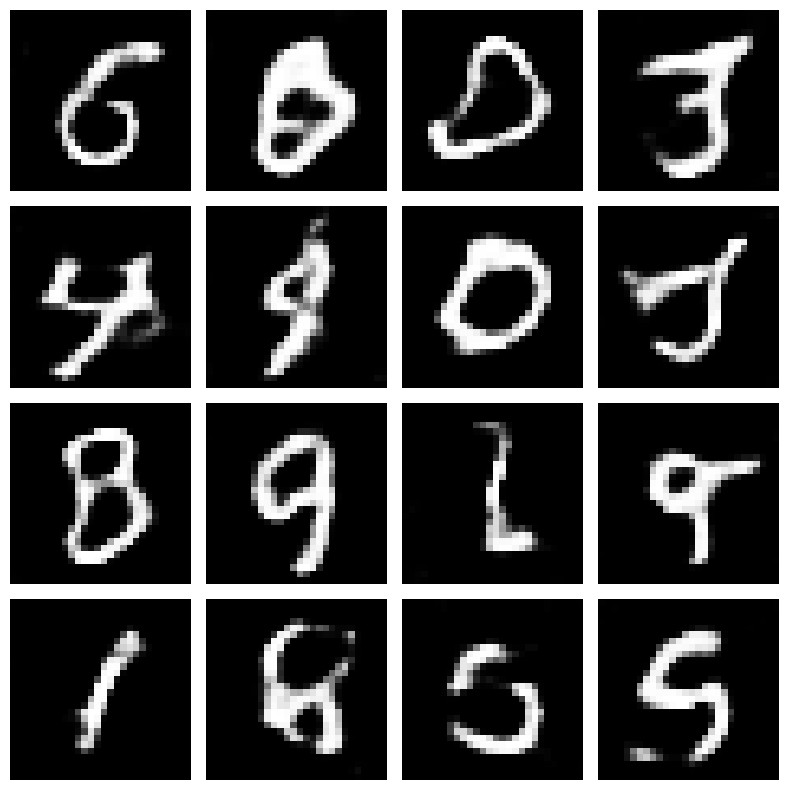

In [16]:
# Step 12: Generate new images
# Final output
# Now our Generator has learned from the MNIST dataset.
# Let's generate 16 new images.
# Generate 16 random noise vectors

noise = tf.random.normal([16, noise_dim])

# Generate images


predictions = generator(noise, training=False)

# Display generated images

plt.figure(figsize=(8, 8))

for i in range(16):

    plt.subplot(4, 4, i + 1)

    # Convert pixel values from -1 to +1 into 0 to 1
    image = (predictions[i, :, :, 0] + 1) / 2

    plt.imshow(image, cmap="gray")

    plt.axis("off")

plt.tight_layout()

plt.show()